<a href="https://colab.research.google.com/github/asnapareeth004-hue/traffic-congestion-prediction/blob/main/02_lstm_traffic_imputation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import requests

from io import BytesIO
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [7]:

# GitHub repository URL
dataset_url = (
    "https://raw.githubusercontent.com/"
    "asnapareeth004-hue/traffic-congestion-prediction/"
    "main/metr_la_preprocessed.npz"
)

# Download the dataset directly from GitHub
response = requests.get(dataset_url, timeout=120)
response.raise_for_status()

data = np.load(BytesIO(response.content), allow_pickle=False)

print("Dataset downloaded successfully!")
print("Available arrays:", data.files)

for key in data.files:
    print(
        f"{key}: shape={data[key].shape}, "
        f"dtype={data[key].dtype}"
    )


Dataset downloaded successfully!
Available arrays: ['train', 'val', 'test', 'mean', 'std']
train: shape=(23990, 207), dtype=float32
val: shape=(3427, 207), dtype=float32
test: shape=(6855, 207), dtype=float32
mean: shape=(207,), dtype=float32
std: shape=(207,), dtype=float32


In [8]:

# Identify arrays by their possible names
keys = {key.lower(): key for key in data.files}

def find_array(*names):
    for name in names:
        if name in keys:
            return np.asarray(data[keys[name]])
    return None

train_raw = find_array("train", "train_data", "x_train")
val_raw = find_array("val", "validation", "val_data", "x_val")
test_raw = find_array("test", "test_data", "x_test")

saved_mean = find_array("mean", "train_mean")
saved_std = find_array("std", "train_std")

# If separate train and test arrays exist
if train_raw is not None and test_raw is not None:

    if val_raw is None:
        # Reserve the last 15% of training data for validation
        split_point = int(len(train_raw) * 0.85)
        val_raw = train_raw[split_point:]
        train_raw = train_raw[:split_point]

# Otherwise, find a complete traffic matrix and split it chronologically
else:
    full_data = find_array(
        "traffic", "data", "values",
        "processed_data", "traffic_data"
    )

    if full_data is None:
        candidates = [
            np.asarray(data[key])
            for key in data.files
            if np.asarray(data[key]).ndim == 2
            and np.asarray(data[key]).shape[1] == 207
        ]

        if len(candidates) != 1:
            raise ValueError(
                "Could not identify the traffic matrix. "
                f"Available arrays: {data.files}"
            )

        full_data = candidates[0]

    full_data = np.asarray(full_data, dtype=np.float32)

    n = len(full_data)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train_raw = full_data[:train_end]
    val_raw = full_data[train_end:val_end]
    test_raw = full_data[val_end:]

# Convert to numeric arrays
train_raw = np.asarray(train_raw, dtype=np.float32)
val_raw = np.asarray(val_raw, dtype=np.float32)
test_raw = np.asarray(test_raw, dtype=np.float32)

print("Train:", train_raw.shape)
print("Validation:", val_raw.shape)
print("Test:", test_raw.shape)


Train: (23990, 207)
Validation: (3427, 207)
Test: (6855, 207)


In [9]:

# Check whether the training data appears to be standardized already
train_col_means = np.nanmean(train_raw, axis=0)
train_col_stds = np.nanstd(train_raw, axis=0)

already_scaled = (
    np.nanmedian(np.abs(train_col_means)) < 5
    and 0.1 < np.nanmedian(train_col_stds) < 3
)

# Use the saved statistics when available
if saved_mean is not None and saved_std is not None:
    mean = np.asarray(saved_mean, dtype=np.float32).reshape(-1)
    std = np.asarray(saved_std, dtype=np.float32).reshape(-1)
else:
    mean = np.nanmean(train_raw, axis=0).astype(np.float32)
    std = np.nanstd(train_raw, axis=0).astype(np.float32)

mean = np.where(np.isfinite(mean), mean, 0.0)
std = np.where(np.isfinite(std) & (std > 1e-6), std, 1.0)

if already_scaled:
    # Keep preprocessed data as it is
    train = train_raw.copy()
    val = val_raw.copy()
    test = test_raw.copy()
    print("Existing scaling detected. No additional scaling applied.")

else:
    # Apply training-set statistics to all splits
    train = (train_raw - mean) / std
    val = (val_raw - mean) / std
    test = (test_raw - mean) / std
    print("Data scaled using training-set statistics.")

n_sensors = train.shape[1]
sensor_cols = [f"sensor_{i}" for i in range(n_sensors)]

print("Number of sensors:", n_sensors)
print("Train:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

print("Missing values in train:", np.isnan(train).sum())


Existing scaling detected. No additional scaling applied.
Number of sensors: 207
Train: (23990, 207)
Validation: (3427, 207)
Test: (6855, 207)
Missing values in train: 0


In [10]:

WINDOW = 12
STRIDE = 6
MASK_RATE = 0.15

def prepare_data(data, seed=42):
    rng = np.random.default_rng(seed)

    sequences = np.array([
        data[i:i + WINDOW]
        for i in range(
            0, len(data) - WINDOW + 1, STRIDE
        )
    ], dtype=np.float32)

    # Only mask existing, observed values
    observed = np.isfinite(sequences)

    artificial_mask = (
        (rng.random(sequences.shape) < MASK_RATE)
        & observed
    )

    corrupted = sequences.copy()
    corrupted[artificial_mask] = np.nan

    # Input: values plus observation indicators
    inputs = np.concatenate([
        np.nan_to_num(corrupted, nan=0.0),
        np.isfinite(corrupted).astype(np.float32)
    ], axis=-1)

    # Target: original values plus artificial-mask indicators
    targets = np.concatenate([
        np.nan_to_num(sequences, nan=0.0),
        artificial_mask.astype(np.float32)
    ], axis=-1)

    return inputs, targets

X_train, y_train = prepare_data(train, seed=42)
X_val, y_val = prepare_data(val, seed=43)
X_test, y_test = prepare_data(test, seed=44)

print("Training input:", X_train.shape)
print("Training target:", y_train.shape)
print("Validation input:", X_val.shape)
print("Test input:", X_test.shape)


Training input: (3997, 12, 414)
Training target: (3997, 12, 414)
Validation input: (570, 12, 414)
Test input: (1141, 12, 414)


In [11]:

inputs = tf.keras.Input(
    shape=(WINDOW, 2 * n_sensors)
)

x = tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(64, return_sequences=True)
)(inputs)

x = tf.keras.layers.Dropout(0.2)(x)

x = tf.keras.layers.LSTM(
    32, return_sequences=True
)(x)

outputs = tf.keras.layers.Dense(n_sensors)(x)

model = tf.keras.Model(inputs, outputs)

def masked_mse(y_true, y_pred):
    target = y_true[..., :n_sensors]
    mask = y_true[..., n_sensors:]

    squared_error = tf.square(target - y_pred) * mask

    return tf.reduce_sum(squared_error) / (
        tf.reduce_sum(mask) + 1e-8
    )

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=masked_mse
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 12, 414)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 12, 128)        │       245,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 12, 32)         │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12, 207)        │         6,831 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 272,687 (1.04 MB)

 Trainable params: 272,687 (1.04 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop]
)


Epoch 1/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - loss: 0.7010 - val_loss: 0.5961
Epoch 2/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.5318 - val_loss: 0.5421
Epoch 3/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - loss: 0.4933 - val_loss: 0.5101
Epoch 4/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.4661 - val_loss: 0.4887
Epoch 5/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.4463 - val_loss: 0.4729
Epoch 6/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.4308 - val_loss: 0.4614
Epoch 7/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.4184 - val_loss: 0.4517
Epoch 8/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.4065 - val_loss: 0.4408
Epoch 9/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.3966 - val_loss: 0.4349
Epoch 10/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.3876 - val_loss: 0.4268
Epoch 11/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.3802 - val_loss: 0.4215
Epoch 12/30
125/125 ━━━━━━━━━━━━━━━━━━━━ 

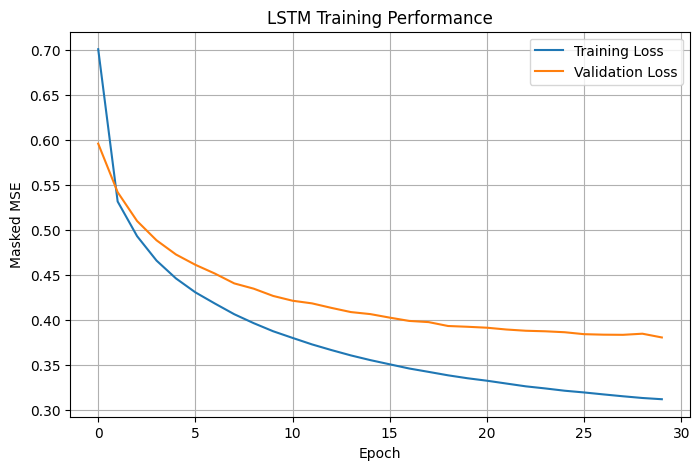

In [13]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Masked MSE")
plt.title("LSTM Training Performance")
plt.legend()
plt.grid(True)
plt.show()


In [14]:

pred_scaled = model.predict(X_test)

true_scaled = y_test[..., :n_sensors]
test_mask = y_test[..., n_sensors:] > 0.5

# Convert predictions and targets back to original units
true_values = true_scaled * std + mean
pred_values = pred_scaled * std + mean

y_true = true_values[test_mask]
y_pred = pred_values[test_mask]

if len(y_true) > 0:
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
else:
    print("No artificially masked test readings were generated.")


36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
MAE: 3.8181
RMSE: 6.3266


In [15]:

model.save("lstm_traffic_imputation.keras")

print("Model saved as lstm_traffic_imputation.keras")


Model saved as lstm_traffic_imputation.keras
